# Step 7 — Ethereum: code, estremi e innovazioni

Diagnostica esplorativa per discutere le anomalie con Alessio. Le statistiche descrittive usano tutti i blocchi;
le innovazioni derivano dalla finestra contigua e dai modelli dello [step 5](../step5/dataset_ethereum.ipynb).

## Contesto e metodo

Fonte: dataset Ethereum [Zenodo 22094893](https://doi.org/10.5281/zenodo.22094893), verificato nello step 1.
Fee originali in wei/gas; log = `log(1 + fee in wei/gas)`. P50/P90 sono quantili delle transazioni incluse ponderati per gas,
non quantili tra blocchi e non garanzie di inclusione. Nessun estremo viene rimosso.

I test di normalità sono diagnostici: autocorrelazione, volatilità e numerosità elevata ne limitano l'interpretazione iid.
Le soglie empiriche e GPD descrivono il campione; non sono previsioni o prove di salti.
Riferimento: [checklist, punto 7](../../../../docs/math_dev/ethereum_eip1559_optimal_stopping_summary.md).

## Risultati osservati

Nel testing locale, la kurtosi in eccesso dei residui log p50/p90 è **28,55/114,54**; Student-t migliora il log score medio di **0,272/0,271**, mentre per X il vantaggio è trascurabile.
La forma GPD di log p50 cambia segno fra soglie: nessuna estrapolazione di coda è sostenuta da questi fit. Cluster delle differenze e non normalità non provano salti.
Le anomalie e le verifiche esterne ancora aperte sono in [findings.md](findings.md).

## Dati e residui della media condizionata

Carichiamo il preprocessing verificato e le innovazioni dello step 5.
Conserviamo numeri di blocco e ruoli per evitare di mescolare stima e verifica futura.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from scipy import stats

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/CONTEXT.md").is_file())
input_directory = root / "outputs/notebook_diagnostics/ethereum/step1"
summary = json.loads((input_directory / "preprocessing_summary.json").read_text())
assert summary["chain_id"] == 1
assert summary["dataset_id"] == "e7b17cfb-320d-4e6c-93c1-06dbc24f312d"
df = pd.read_parquet(input_directory / "ethereum_blocks_diagnostics.parquet")
assert len(df) == summary["rows"]
assert df["block_number"].diff().iloc[1:].eq(1).all()
output_directory = root / "outputs/notebook_diagnostics/ethereum/step7"
output_directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.2,
    }
)
pd.set_option("display.max_rows", 24)
pd.set_option("display.max_columns", 12)
labels = {
    "X": "Utilizzo X",
    "log_effective_priority_fee_per_gas_p50": "Log priority fee p50",
    "log_effective_priority_fee_per_gas_p90": "Log priority fee p90",
    "priority_fee_dispersion": "Dispersione log p90 − log p50",
}
print("Fonte: Zenodo 22094893; SHA-256:", summary["dataset_sha256"])
print("Blocchi:", df.block_number.iloc[0], "–", df.block_number.iloc[-1], "N =", len(df))

residual_path = root / "outputs/notebook_diagnostics/ethereum/step5/mean_residuals.parquet"
if not residual_path.is_file():
    raise FileNotFoundError("Eseguire prima lo step 5 per produrre mean_residuals.parquet.")
residuals = pd.read_parquet(residual_path)
residual_scope = json.loads((residual_path.parent / "analysis_scope.json").read_text())
assert residual_scope["dataset_id"] == summary["dataset_id"]
assert residual_scope["dataset_sha256"] == summary["dataset_sha256"]
residual_columns = ["residual_X", "residual_log_p50", "residual_log_p90", "residual_dispersion"]
assert residuals.block_number.diff().iloc[1:].eq(1).all()
assert residuals[residual_columns].notna().all().all()
source_rows = df.set_index("block_number").loc[residuals.block_number]
assert np.array_equal(source_rows.timestamp.to_numpy(), residuals.timestamp.to_numpy())
for column in [
    "X",
    "log_effective_priority_fee_per_gas_p50",
    "log_effective_priority_fee_per_gas_p90",
    "priority_fee_dispersion",
]:
    assert np.allclose(source_rows[column].to_numpy(), residuals[column].to_numpy())
assert set(residuals.role) == {"training", "validation", "testing"}
assert (
    residuals.loc[residuals.role.eq("training"), "block_number"].max()
    < residuals.loc[residuals.role.eq("testing"), "block_number"].min()
)
display(
    residuals.groupby("role", sort=False).agg(
        N=("block_number", "size"),
        primo_blocco=("block_number", "min"),
        ultimo_blocco=("block_number", "max"),
    )
)
print("Residui in-sample nel training; previsioni rolling nello step5 per validation/testing.")

Fonte: Zenodo 22094893; SHA-256: 4a8482552e3730ad68243a042eaa92b112450b36411f11a18947e9682d2e62e0
Blocchi: 23935694 – 25590229 N = 1654536


,N,primo_blocco,ultimo_blocco
role,,,
training,19990,25560240,25580229
validation,5000,25580230,25585229
testing,5000,25585230,25590229


Residui in-sample nel training; previsioni rolling nello step5 per validation/testing.


## 7.1 — Segnalazioni IQR senza eliminazioni

Ripetiamo il controllo originale sugli estremi, conservando tutte le righe.
Un IQR nullo o una distribuzione asimmetrica possono generare molti segnali senza errori nei dati.

In [2]:
def detect_outliers_iqr(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)


assert detect_outliers_iqr(pd.Series([1, 1, 1, 1, 100])).tolist() == [
    False,
    False,
    False,
    False,
    True,
]
fee_columns = [
    "base_fee_per_gas",
    "effective_priority_fee_per_gas_p50",
    "effective_priority_fee_per_gas_p90",
]
iqr_rows = []
for column in fee_columns + ["gas_used", "gas_limit", "tx_count"]:
    df[column + "_outlier"] = detect_outliers_iqr(df[column])
    iqr_rows.append(
        {
            "variabile": column,
            "segnali": int(df[column + "_outlier"].sum()),
            "quota": float(df[column + "_outlier"].mean()),
        }
    )
iqr_report = pd.DataFrame(iqr_rows)
display(iqr_report)
iqr_report.to_csv(output_directory / "outlier_report.csv", index=False)

,variabile,segnali,quota
0,base_fee_per_gas,172881,0.104489
1,effective_priority_fee_per_gas_p50,212694,0.128552
2,effective_priority_fee_per_gas_p90,77683,0.046952
3,gas_used,0,0.000000
4,gas_limit,364129,0.220079
5,tx_count,89382,0.054022


## 7.2 — Asimmetria e kurtosi di variabili e residui

Misuriamo asimmetria e kurtosi in eccesso sia prima sia dopo la previsione della media.
Separiamo così la forma dei livelli dalla forma delle innovazioni; non assumiamo che siano iid.

In [3]:
shape_rows = []
original_columns = fee_columns + list(labels) + ["delta_X", "delta_log_p50", "delta_log_p90"]
for origin, frame, columns in [
    ("campione completo", df, original_columns),
    ("residui test rolling", residuals[residuals.role.eq("testing")], residual_columns),
]:
    for column in columns:
        values = frame[column].dropna().to_numpy()
        shape_rows.append(
            {
                "campione": origin,
                "variabile": column,
                "N": len(values),
                "skewness": stats.skew(values, bias=False),
                "kurtosi_eccesso": stats.kurtosis(values, fisher=True, bias=False),
            }
        )
shape_report = pd.DataFrame(shape_rows)
display(shape_report.round(4))
shape_report.to_csv(output_directory / "shape_report.csv", index=False)

,campione,variabile,N,skewness,kurtosi_eccesso
0,campione completo,base_fee_per_gas,1654536,18.0431,538.9226
1,campione completo,effective_priority_fee_per_gas_p50,1654536,570.1871,448240.8798
2,campione completo,effective_priority_fee_per_gas_p90,1654536,240.7056,82726.3965
3,campione completo,X,1654536,0.4614,-0.2903
4,campione completo,log_effective_priority_fee_per_gas_p50,1654536,-2.1931,8.2487
5,campione completo,log_effective_priority_fee_per_gas_p90,1654536,-4.7793,57.6386
6,campione completo,priority_fee_dispersion,1654536,2.8438,12.5387
7,campione completo,delta_X,1654535,0.3026,0.0021
8,campione completo,delta_log_p50,1654535,0.0587,8.5849
9,campione completo,delta_log_p90,1654535,-0.0128,41.2787


## 7.3 — Q-Q plot rispetto alla normale

Confrontiamo quantili standardizzati osservati con quelli gaussiani per livelli trasformati e residui test.
Usiamo quantili deterministici: le code restano visibili senza disegnare milioni di punti.

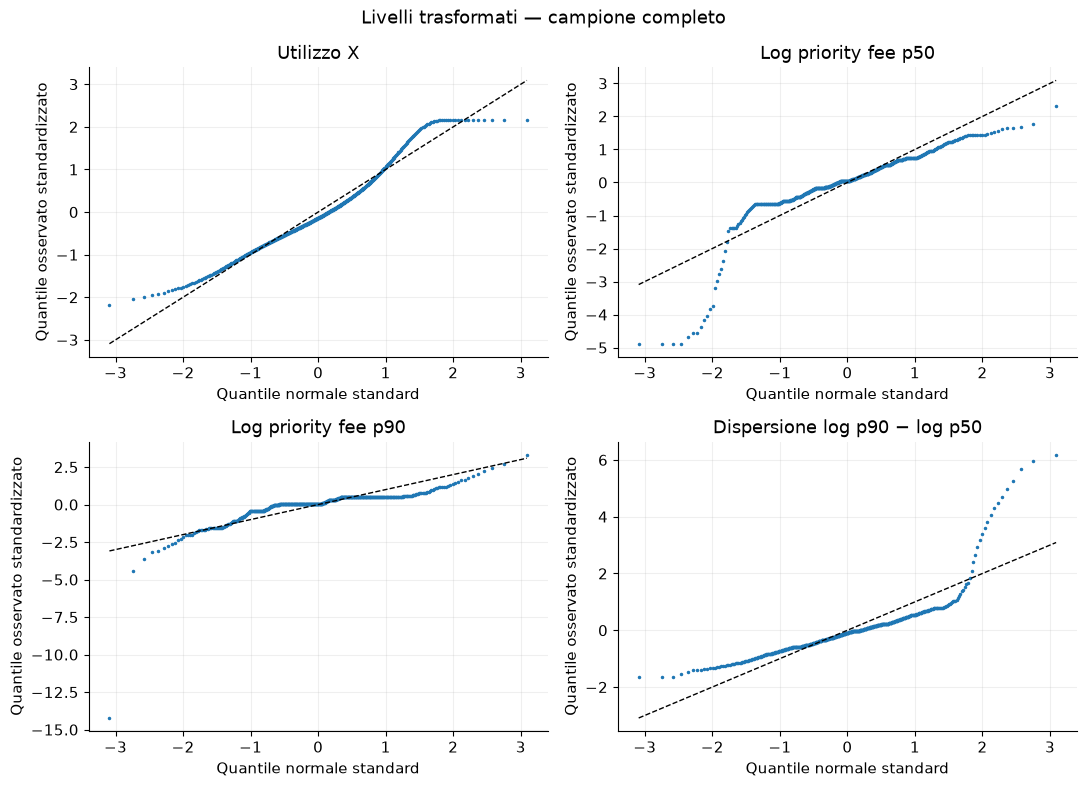

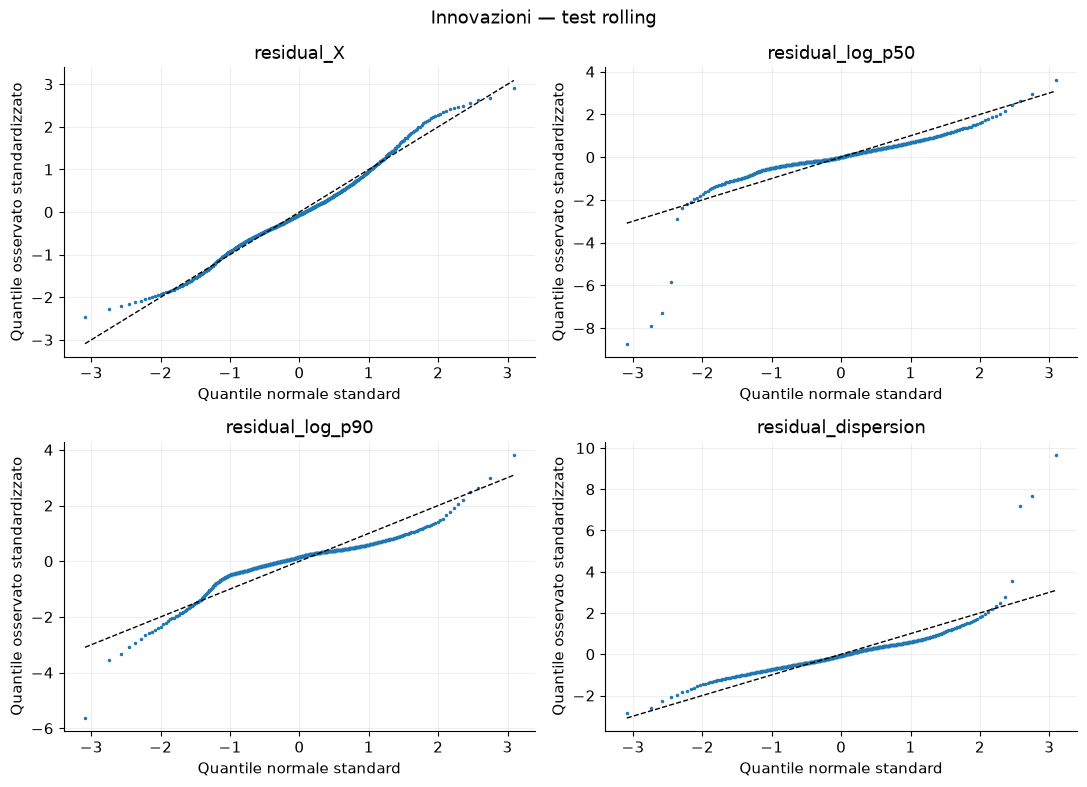

In [4]:
for frame, columns, title in [
    (df, list(labels), "Livelli trasformati — campione completo"),
    (residuals[residuals.role.eq("testing")], residual_columns, "Innovazioni — test rolling"),
]:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    probabilities = np.linspace(0.001, 0.999, 499)
    theoretical = stats.norm.ppf(probabilities)
    for ax, column in zip(axes.flat, columns, strict=True):
        values = frame[column].dropna().to_numpy()
        observed = (np.quantile(values, probabilities) - values.mean()) / values.std(ddof=1)
        ax.plot(theoretical, observed, ".", markersize=3)
        ax.plot(theoretical, theoretical, "--", color="black", linewidth=1)
        ax.set(
            title=labels.get(column, column),
            xlabel="Quantile normale standard",
            ylabel="Quantile osservato standardizzato",
        )
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 7.4 — Jarque–Bera come controllo complementare

Aggiungiamo il test di normalità alle misure di forma e ai Q-Q plot.
Il p-value asintotico iid non corregge dipendenza seriale o volatilità e non dimostra la presenza di salti.

In [5]:
jb_rows = []
for origin, frame, columns in [
    ("campione completo", df, original_columns),
    ("residui test rolling", residuals[residuals.role.eq("testing")], residual_columns),
]:
    for column in columns:
        result = stats.jarque_bera(frame[column].dropna())
        jb_rows.append(
            {
                "campione": origin,
                "variabile": column,
                "JB": result.statistic,
                "p_value_iid": result.pvalue,
            }
        )
jb_report = pd.DataFrame(jb_rows)
display(jb_report)
jb_report.to_csv(output_directory / "jarque_bera.csv", index=False)

,campione,variabile,JB,p_value_iid
0,campione completo,base_fee_per_gas,2.011212e+10,0.000000e+00
1,campione completo,effective_priority_fee_per_gas_p50,1.385122e+16,0.000000e+00
2,campione completo,effective_priority_fee_per_gas_p90,4.718080e+14,0.000000e+00
3,campione completo,X,6.450885e+04,0.000000e+00
4,campione completo,log_effective_priority_fee_per_gas_p50,6.017016e+06,0.000000e+00
5,campione completo,log_effective_priority_fee_per_gas_p90,2.353267e+08,0.000000e+00
6,campione completo,priority_fee_dispersion,1.306850e+07,0.000000e+00
7,campione completo,delta_X,2.524441e+04,0.000000e+00
8,campione completo,delta_log_p50,5.081716e+06,0.000000e+00
9,campione completo,delta_log_p90,1.174665e+08,0.000000e+00


## 7.5 — Frequenza e ampiezza delle eccedenze

Contiamo le osservazioni oltre i quantili 99% e 99,9% delle fee e delle variazioni assolute.
I quantili sono stimati sullo stesso campione: la frequenza è descrittiva e dipende anche dai valori ripetuti.

In [6]:
exceedance_rows = []
for column in [
    "base_fee_gwei",
    "priority_fee_p50_gwei",
    "priority_fee_p90_gwei",
    "delta_X",
    "delta_log_p50",
    "delta_log_p90",
]:
    values = df[column].abs() if column.startswith("delta_") else df[column]
    for probability in [0.99, 0.999]:
        threshold = values.quantile(probability)
        excess = values[values > threshold] - threshold
        exceedance_rows.append(
            {
                "variabile": column,
                "quantile": probability,
                "soglia": threshold,
                "N_eccedenze": len(excess),
                "quota": len(excess) / values.notna().sum(),
                "eccedenza_media": excess.mean(),
                "eccedenza_massima": excess.max(),
            }
        )
exceedance_report = pd.DataFrame(exceedance_rows)
display(exceedance_report.round(5))
exceedance_report.to_csv(output_directory / "empirical_exceedances.csv", index=False)

,variabile,quantile,soglia,N_eccedenze,quota,eccedenza_media,eccedenza_massima
0,base_fee_gwei,0.990,2.89228,16546,0.01000,3.45380,46.85374
1,base_fee_gwei,0.999,10.85515,1655,0.00100,7.09232,38.89087
2,priority_fee_p50_gwei,0.990,1.92525,16546,0.01000,13.67249,13489.96807
3,priority_fee_p50_gwei,0.999,18.30930,1655,0.00100,111.43326,13473.58402
4,priority_fee_p90_gwei,0.990,16.00000,16533,0.00999,57.20816,13475.89332
5,priority_fee_p90_gwei,0.999,117.51788,1655,0.00100,275.72165,13374.37544
6,delta_X,0.990,1.75613,16546,0.01000,0.08191,0.24385
7,delta_X,0.999,1.92334,1655,0.00100,0.03810,0.07664
8,delta_log_p50,0.990,16.57725,16546,0.01000,2.17166,12.81420
9,delta_log_p50,0.999,20.79023,1655,0.00100,1.79710,8.60122


## 7.6 — Cluster temporali degli estremi

Confrontiamo la frequenza di due estremi adiacenti con quella attesa sotto indipendenza.
Usiamo l'ordine dei blocchi completo e contiamo i cluster senza comprimere gli intervalli tra eventi.

Un picco seguito da rientro può produrre due grandi differenze adiacenti: questo clustering può essere meccanico.

,variabile,soglia_abs_q99,eventi,cluster_adiacenti,quota_eventi,P_estremo_dopo_estremo,rapporto_vs_indipendenza
0,delta_X,1.756126,16546,14763,0.01,0.107760,10.775595
1,delta_log_p50,16.577255,16546,11146,0.01,0.326363,32.635005
2,delta_log_p90,5.668563,16546,10121,0.01,0.388311,38.829612


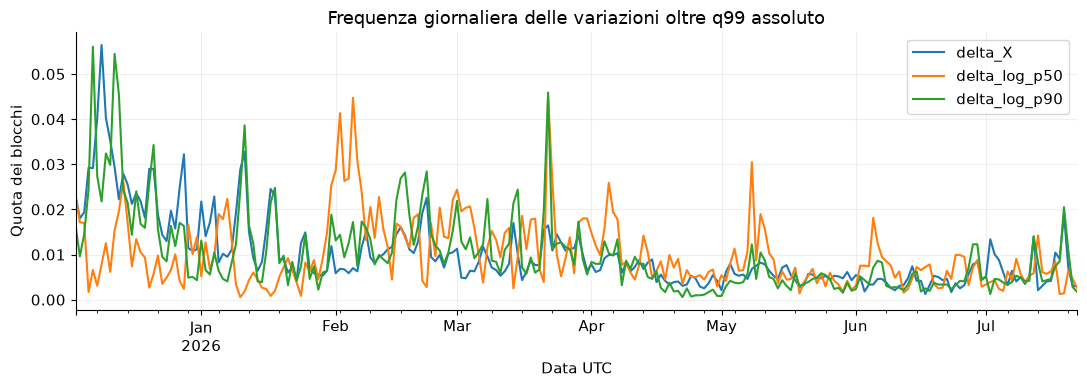

In [7]:
cluster_rows = []
for column in ["delta_X", "delta_log_p50", "delta_log_p90"]:
    values = df[column].abs().to_numpy()
    finite = np.isfinite(values)
    threshold = np.nanquantile(values, 0.99)
    extreme = finite & (values > threshold)
    adjacent = finite[:-1] & finite[1:]
    after_extreme = extreme[:-1] & adjacent
    starts = extreme & ~np.r_[False, extreme[:-1]]
    frequency = extreme[finite].mean()
    conditional = extreme[1:][after_extreme].mean() if after_extreme.any() else np.nan
    cluster_rows.append(
        {
            "variabile": column,
            "soglia_abs_q99": threshold,
            "eventi": int(extreme.sum()),
            "cluster_adiacenti": int(starts.sum()),
            "quota_eventi": frequency,
            "P_estremo_dopo_estremo": conditional,
            "rapporto_vs_indipendenza": conditional / frequency,
        }
    )
cluster_report = pd.DataFrame(cluster_rows)
display(cluster_report)
cluster_report.to_csv(output_directory / "extreme_clustering.csv", index=False)
dates = pd.to_datetime(df.timestamp, unit="s", utc=True)
daily_extremes = pd.DataFrame(index=dates)
for column in ["delta_X", "delta_log_p50", "delta_log_p90"]:
    values = df[column].abs()
    daily_extremes[column] = (values > values.quantile(0.99)).to_numpy()
ax = daily_extremes.resample("1D").mean().plot(figsize=(11, 4))
ax.set(
    title="Frequenza giornaliera delle variazioni oltre q99 assoluto",
    xlabel="Data UTC",
    ylabel="Quota dei blocchi",
)
plt.tight_layout()
plt.show()
plt.close()

## 7.7 — Code positive e negative

Separiamo gli shock dei residui test per segno e ne confrontiamo frequenze e ampiezze.
Le soglie inferiore e superiore sono fissate sui residui training, senza consultare il test.

In [8]:
signed_rows = []
for column in residual_columns:
    train = residuals.loc[residuals.role.eq("training"), column]
    test = residuals.loc[residuals.role.eq("testing"), column]
    for sign, threshold in [("negativa", train.quantile(0.01)), ("positiva", train.quantile(0.99))]:
        tail = test[test < threshold] if sign == "negativa" else test[test > threshold]
        signed_rows.append(
            {
                "variabile": column,
                "coda": sign,
                "soglia_training": threshold,
                "N_test": len(test),
                "eventi_test": len(tail),
                "quota_test": len(tail) / len(test),
                "shock_medio": tail.mean(),
                "shock_massimo_assoluto": tail.abs().max(),
            }
        )
signed_report = pd.DataFrame(signed_rows)
display(signed_report)
signed_report.to_csv(output_directory / "signed_extremes.csv", index=False)

,variabile,coda,soglia_training,N_test,eventi_test,quota_test,shock_medio,shock_massimo_assoluto
0,residual_X,negativa,-0.907620,5000,15,0.0030,-0.972570,1.098029
1,residual_X,positiva,1.034226,5000,30,0.0060,1.091276,1.195316
2,residual_log_p50,negativa,-4.773678,5000,49,0.0098,-12.316144,18.240042
3,residual_log_p50,positiva,4.404797,5000,40,0.0080,5.684383,9.593316
4,residual_log_p90,negativa,-4.364982,5000,9,0.0018,-9.580994,20.826244
5,residual_log_p90,positiva,2.307658,5000,35,0.0070,2.838687,4.009976
6,residual_dispersion,negativa,-4.112951,5000,22,0.0044,-4.709754,6.064657
7,residual_dispersion,positiva,4.826347,5000,42,0.0084,11.963160,18.171511


## 7.8 — Innovazioni Gaussiane e Student-t fuori campione

Stimiamo normale e Student-t solo sui residui training, poi confrontiamo log score sul test rolling.
Una densità marginale migliore non elimina l'eteroschedasticità dello step 6 né garantisce un kernel di transizione adeguato.

In [9]:
distribution_rows = []
for column in residual_columns:
    train = residuals.loc[residuals.role.eq("training"), column].to_numpy()
    test = residuals.loc[residuals.role.eq("testing"), column].to_numpy()
    normal_parameters = stats.norm.fit(train)
    t_parameters = stats.t.fit(train)
    assert normal_parameters[1] > 0 and t_parameters[0] > 0 and t_parameters[2] > 0
    normal_score = stats.norm.logpdf(test, *normal_parameters)
    t_score = stats.t.logpdf(test, *t_parameters)
    score_difference = pd.Series(t_score - normal_score)
    # La media delle differenze è accompagnata da incertezza HAC, non da errori iid.
    difference_fit = sm.OLS(score_difference, np.ones((len(test), 1))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 50}
    )
    lower, upper = difference_fit.conf_int().iloc[0]
    distribution_rows.append(
        {
            "variabile": column,
            "N_training": len(train),
            "N_test": len(test),
            "t_gradi_liberta": t_parameters[0],
            "logscore_normale": normal_score.mean(),
            "logscore_t": t_score.mean(),
            "guadagno_t": score_difference.mean(),
            "HAC95_inferiore": lower,
            "HAC95_superiore": upper,
        }
    )
distribution_report = pd.DataFrame(distribution_rows)
display(distribution_report.round(5))
distribution_report.to_csv(output_directory / "innovation_distributions.csv", index=False)

,variabile,N_training,N_test,t_gradi_liberta,logscore_normale,logscore_t,guadagno_t,HAC95_inferiore,HAC95_superiore
0,residual_X,19990,5000,6.228787e+09,-0.52355,-0.52355,0.00000,0.00000,0.00000
1,residual_log_p50,19990,5000,3.284970e+00,-2.05393,-1.78195,0.27197,0.20880,0.33515
2,residual_log_p90,19990,5000,2.601660e+00,-1.44108,-1.17032,0.27076,0.20636,0.33515
3,residual_dispersion,19990,5000,3.779760e+00,-1.96324,-1.72878,0.23446,0.16808,0.30083


## 7.9 — Forma empirica delle code

Tracciamo la sopravvivenza delle variazioni assolute nelle code superiori a q95.
Il grafico usa quantili del campione completo e non presuppone una legge di potenza.

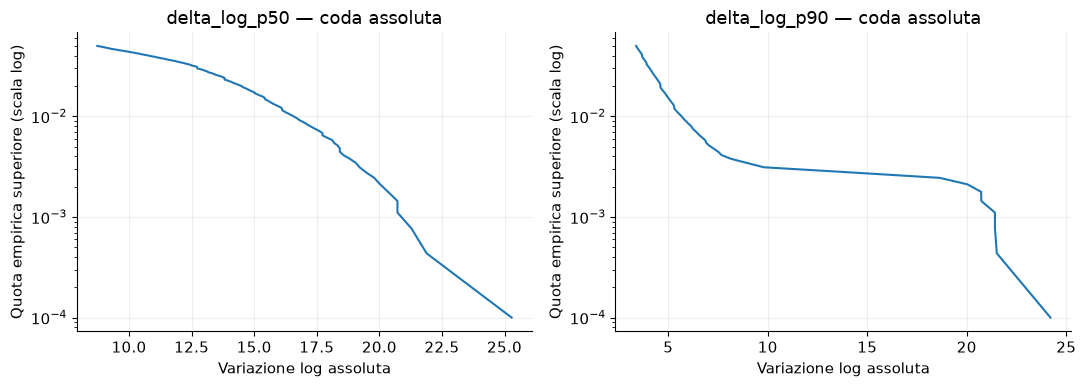

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
probabilities = np.linspace(0.95, 0.9999, 150)
for ax, column in zip(axes, ["delta_log_p50", "delta_log_p90"], strict=True):
    values = df[column].abs().dropna()
    ax.plot(values.quantile(probabilities), 1 - probabilities)
    ax.set_yscale("log")
    ax.set(
        title=column + " — coda assoluta",
        xlabel="Variazione log assoluta",
        ylabel="Quota empirica superiore (scala log)",
    )
fig.tight_layout()
plt.show()
plt.close(fig)

## 7.10 — GPD esplorativa e sensibilità della soglia

Valutiamo le code assolute dei residui training con soglie 95%, 97,5% e 99%.
Raggruppiamo eccedenze distanti al massimo cinque blocchi e adattiamo la GPD solo ad almeno 50 massimi di cluster.

In [11]:
def cluster_maxima(block_numbers, values, threshold, separation=5):
    positions = np.flatnonzero(values > threshold)
    if not len(positions):
        return np.array([], dtype=float)
    groups = np.cumsum(np.r_[True, np.diff(block_numbers[positions]) > separation])
    return pd.Series(values[positions] - threshold).groupby(groups).max().to_numpy()


assert np.array_equal(
    cluster_maxima(np.arange(12), np.array([0, 5, 6, 0, 0, 0, 0, 0, 0, 0, 7, 0]), 4), [2, 3]
)
assert cluster_maxima(np.arange(3), np.zeros(3), 1).size == 0
gpd_rows = []
training = residuals[residuals.role.eq("training")]
for column in residual_columns:
    values = training[column].abs().to_numpy()
    for probability in [0.95, 0.975, 0.99]:
        threshold = np.quantile(values, probability)
        peaks = cluster_maxima(training.block_number.to_numpy(), values, threshold)
        row = {
            "variabile": column,
            "quantile": probability,
            "soglia_abs": threshold,
            "cluster": len(peaks),
            "xi": np.nan,
            "scala": np.nan,
            "stato": "campione insufficiente (<50 cluster)",
        }
        if len(peaks) >= 50:
            xi, _, scale = stats.genpareto.fit(peaks, floc=0)
            row.update(xi=xi, scala=scale, stato="esplorativo: soglia e declustering da validare")
        gpd_rows.append(row)
gpd_report = pd.DataFrame(gpd_rows)
display(gpd_report.round(5))
gpd_report.to_csv(output_directory / "gpd_threshold_sensitivity.csv", index=False)
print(
    "GPD su |residuo|: non distingue code di segno opposto; non usarla per "
    "estrapolazione senza validazione separata."
)

,variabile,quantile,soglia_abs,cluster,xi,scala,stato
0,residual_X,0.950,0.88629,674,-0.15325,0.11579,esplorativo: soglia e declustering da validare
1,residual_X,0.975,0.95293,354,-0.27822,0.12688,esplorativo: soglia e declustering da validare
2,residual_X,0.990,1.05108,148,-0.33694,0.10826,esplorativo: soglia e declustering da validare
3,residual_log_p50,0.950,3.63114,619,0.79383,0.94943,esplorativo: soglia e declustering da validare
4,residual_log_p50,0.975,4.30183,357,0.83814,1.44288,esplorativo: soglia e declustering da validare
5,residual_log_p50,0.990,6.04819,144,-1.31697,15.17686,esplorativo: soglia e declustering da validare
6,residual_log_p90,0.950,2.46281,669,0.11242,1.55718,esplorativo: soglia e declustering da validare
7,residual_log_p90,0.975,3.43506,426,0.23259,1.22245,esplorativo: soglia e declustering da validare
8,residual_log_p90,0.990,4.53802,188,0.28517,1.36274,esplorativo: soglia e declustering da validare
9,residual_dispersion,0.950,3.38663,630,0.59013,1.11732,esplorativo: soglia e declustering da validare


GPD su |residuo|: non distingue code di segno opposto; non usarla per estrapolazione senza validazione separata.


## 7.11 — Eventi reali, salti e feedback al preprocessing

Rileggiamo le verifiche RPC già conservate e isoliamo i casi ancora aperti.
Né non normalità né cluster provano salti: distinguiamo eventi da chiarire, dipendenza residua e possibili regimi.

In [12]:
review_path = input_directory / "extreme_rpc_review.csv"
if review_path.is_file():
    review = pd.read_csv(review_path)
    display(review[["block_number", "status", "detail"]])
    print(
        "Fonte RPC originaria, non indipendente; risultati salvati, nessuna nuova "
        "richiesta di rete."
    )
else:
    print("Verifica esterna non disponibile: nessuna conclusione sulla genuinità dei picchi.")
print("Picco priority fee incluso nel campione:")
peak = df.loc[
    [df.priority_fee_p50_gwei.idxmax()],
    ["block_number", "priority_fee_p50_gwei", "priority_fee_p90_gwei", "X", "tx_count"],
]
display(peak)
print(
    "Feedback step1: conservare gli estremi; la verifica strutturale non "
    "certifica le transazioni del picco."
)
print(
    "Cluster suggeriscono di confrontare volatilità/regimi prima di introdurre "
    "salti o mixture; non stimiamo modelli non richiesti."
)
print("Un singolo picco seguito da rientro può creare due differenze estreme consecutive.")
print("Il cluster delle differenze da solo non prova self-excitation o cambiamenti di regime.")

,block_number,status,detail
0,23935721,confermato,NaN
1,23936194,confermato,NaN
2,23937276,non_verificato,ValueError: Il servizio RPC non ha restituito ...
3,23937277,non_verificato,ValueError: Il servizio RPC non ha restituito ...
4,23937362,confermato,NaN
5,23941348,confermato,NaN
6,23980771,confermato,NaN
7,24130293,confermato,NaN
8,24394185,confermato,NaN
9,24743487,non_verificato,ValueError: Il servizio RPC non ha restituito ...


Fonte RPC originaria, non indipendente; risultati salvati, nessuna nuova richiesta di rete.
Picco priority fee incluso nel campione:


,block_number,priority_fee_p50_gwei,priority_fee_p90_gwei,X,tx_count
807793,24743487,13491.893323,13491.893323,0.163707,12


Feedback step1: conservare gli estremi; la verifica strutturale non certifica le transazioni del picco.
Cluster suggeriscono di confrontare volatilità/regimi prima di introdurre salti o mixture; non stimiamo modelli non richiesti.
Un singolo picco seguito da rientro può creare due differenze estreme consecutive.
Il cluster delle differenze da solo non prova self-excitation o cambiamenti di regime.


## Risultati e limiti per Alessio

Raccogliamo i segnali emersi senza trasformare test esplorativi in decisioni automatiche.
I CSV conservano tutte le stime; il findings.md associato riporta soltanto le anomalie verificate nella presente esecuzione.

In [13]:
print("Serie con JB iid < 1%:", int(jb_report.p_value_iid.lt(0.01).sum()), "/", len(jb_report))
display(cluster_report[["variabile", "rapporto_vs_indipendenza"]])
display(distribution_report[["variabile", "guadagno_t", "HAC95_inferiore", "HAC95_superiore"]])
print(
    "I risultati sui residui riguardano soltanto i blocchi",
    residuals.block_number.min(),
    "–",
    residuals.block_number.max(),
)
print(
    "Non sono prove di errori, salti o superiorità generalizzabile; GPD solo "
    "esplorativa, nessuna osservazione esclusa."
)
print("Report salvati in", output_directory)

Serie con JB iid < 1%: 14 / 14


,variabile,rapporto_vs_indipendenza
0,delta_X,10.775595
1,delta_log_p50,32.635005
2,delta_log_p90,38.829612


,variabile,guadagno_t,HAC95_inferiore,HAC95_superiore
0,residual_X,2.333793e-07,1.937303e-07,2.730282e-07
1,residual_log_p50,2.719748e-01,2.088044e-01,3.351451e-01
2,residual_log_p90,2.707570e-01,2.063607e-01,3.351533e-01
3,residual_dispersion,2.344553e-01,1.680821e-01,3.008284e-01


I risultati sui residui riguardano soltanto i blocchi 25560240 – 25590229
Non sono prove di errori, salti o superiorità generalizzabile; GPD solo esplorativa, nessuna osservazione esclusa.
Report salvati in /Users/emanuelelippi/Library/Mobile Documents/com~apple~CloudDocs/Universita/Ricerca/Montori/kairos/outputs/notebook_diagnostics/ethereum/step7
